In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud
import nltk
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import BaggingClassifier

In [ ]:
df = pd.read_csv(r"D:\0--ALL_GitHub_Projects\ML_Project_SMS_SPAM_Classifier\data\raw\spam.csv",encoding='latin-1')

In [4]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1880,ham,Just seeing your missed call my dear brother. ...,NaN,NaN,NaN
5227,ham,I re-met alex nichols from middle school and i...,NaN,NaN,NaN
4677,ham,It is a good thing I'm now getting the connect...,NaN,NaN,NaN
2796,ham,If I get there before you after your ten billi...,NaN,NaN,NaN
2084,ham,How are you. Wish you a great semester,NaN,NaN,NaN


# Data Cleaning

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
# Droping columns
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [7]:
# Rename columns
df.rename(columns={'v1':'target','v2':'text'},inplace=True)

In [8]:
# Checking missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [9]:
# Checking duplicate values
df.duplicated().sum()

np.int64(403)

In [10]:
# Drop duplicated values
df.drop_duplicates(keep='first',inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
# Fit encoder on target variable 
encoder=LabelEncoder()
df['target']=encoder.fit_transform(df['target'])

In [13]:
df.sample(5)

,target,text
1526,0,"Wow ... I love you sooo much, you know ? I can..."
437,0,How long does applebees fucking take
3051,0,Please leave this topic..sorry for telling that..
2973,0,"I'll text carlos and let you know, hang on"
249,1,Congratulations ur awarded 500 of CD vouchers ...


# EDA

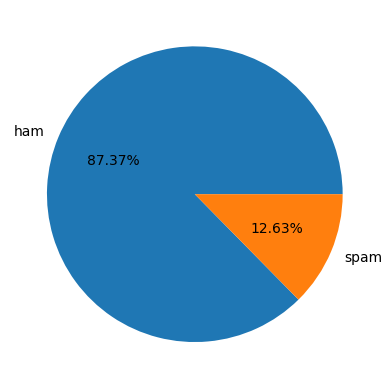

In [14]:
# pie chart
plt.pie(df['target'].value_counts(),autopct='%0.2f%%',labels=['ham','spam'])
plt.show()

## Feature engineering

In [15]:
df['num_characters']=df['text'].apply(len)

In [16]:
df['num_words']=df['text'].apply(lambda x : len(nltk.word_tokenize(x)) )

In [17]:
df['num_sentences']=df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [18]:
df.sample(5)

,target,text,num_characters,num_words,num_sentences
4369,1,Do you want a new Video handset? 750 any time ...,135,29,5
1259,0,We have sent JD for Customer Service cum Accou...,97,19,1
1223,0,Rofl betta invest in some anti aging products,46,8,1
3048,0,Lol they don't know about my awesome phone. I ...,85,20,2
3148,0,"Sorry, in meeting I'll call you later",38,9,1


In [19]:
df[df['target']==0][['num_characters'	,'num_words'	,'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [20]:
df[df['target']==1][['num_characters'	,'num_words'	,'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_characters', ylabel='Count'>

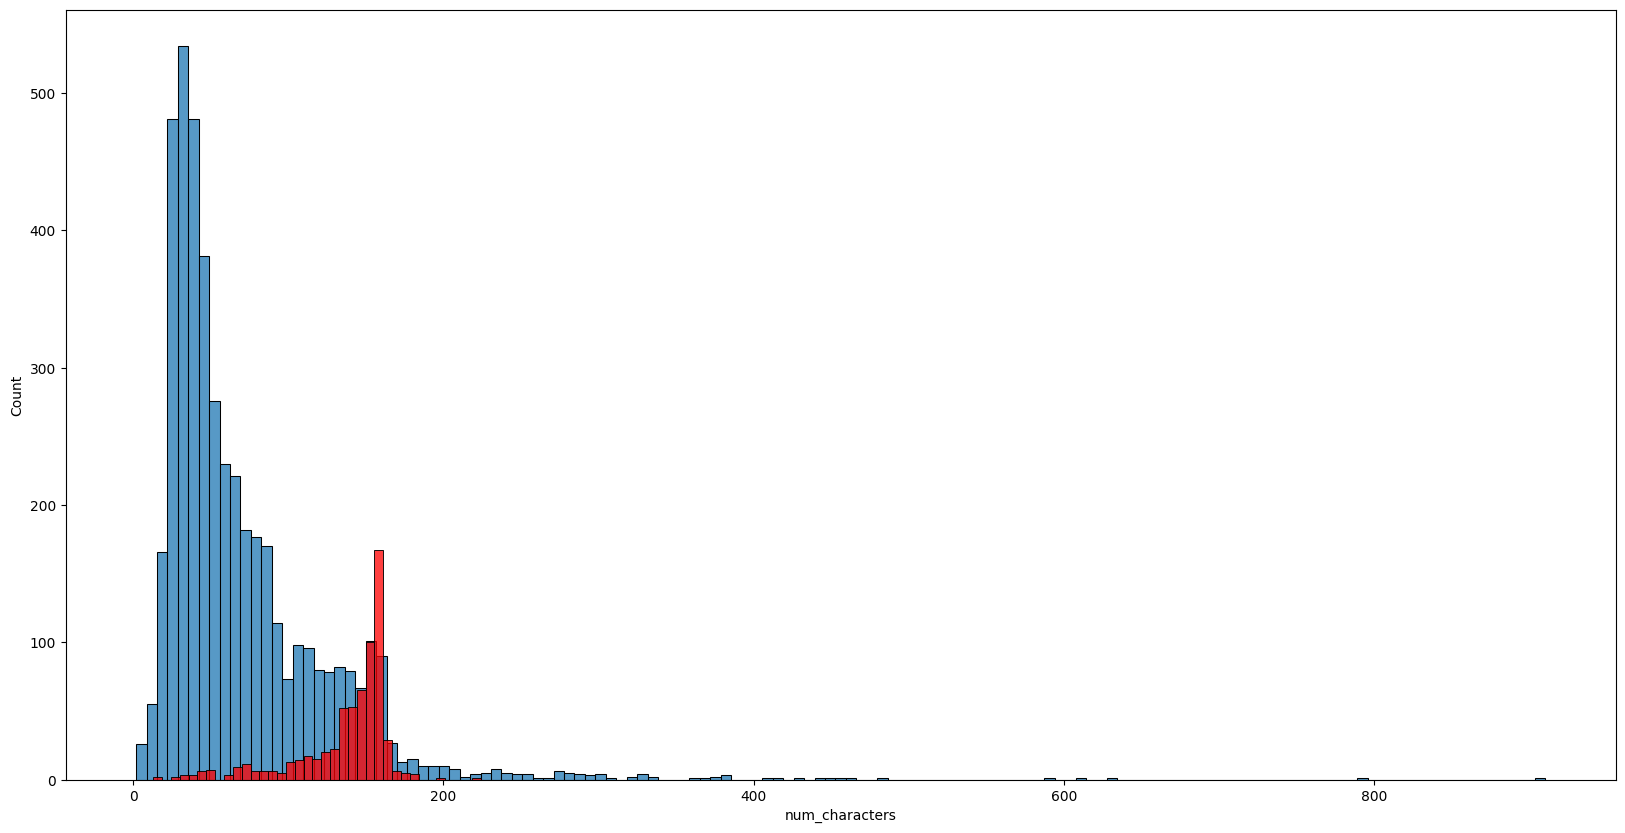

In [21]:
plt.figure(figsize=(20,10))
sns.histplot(df[df['target']==0]['num_characters'])
sns.histplot(df[df['target']==1]['num_characters'],color='red')

<Axes: xlabel='num_words', ylabel='Count'>

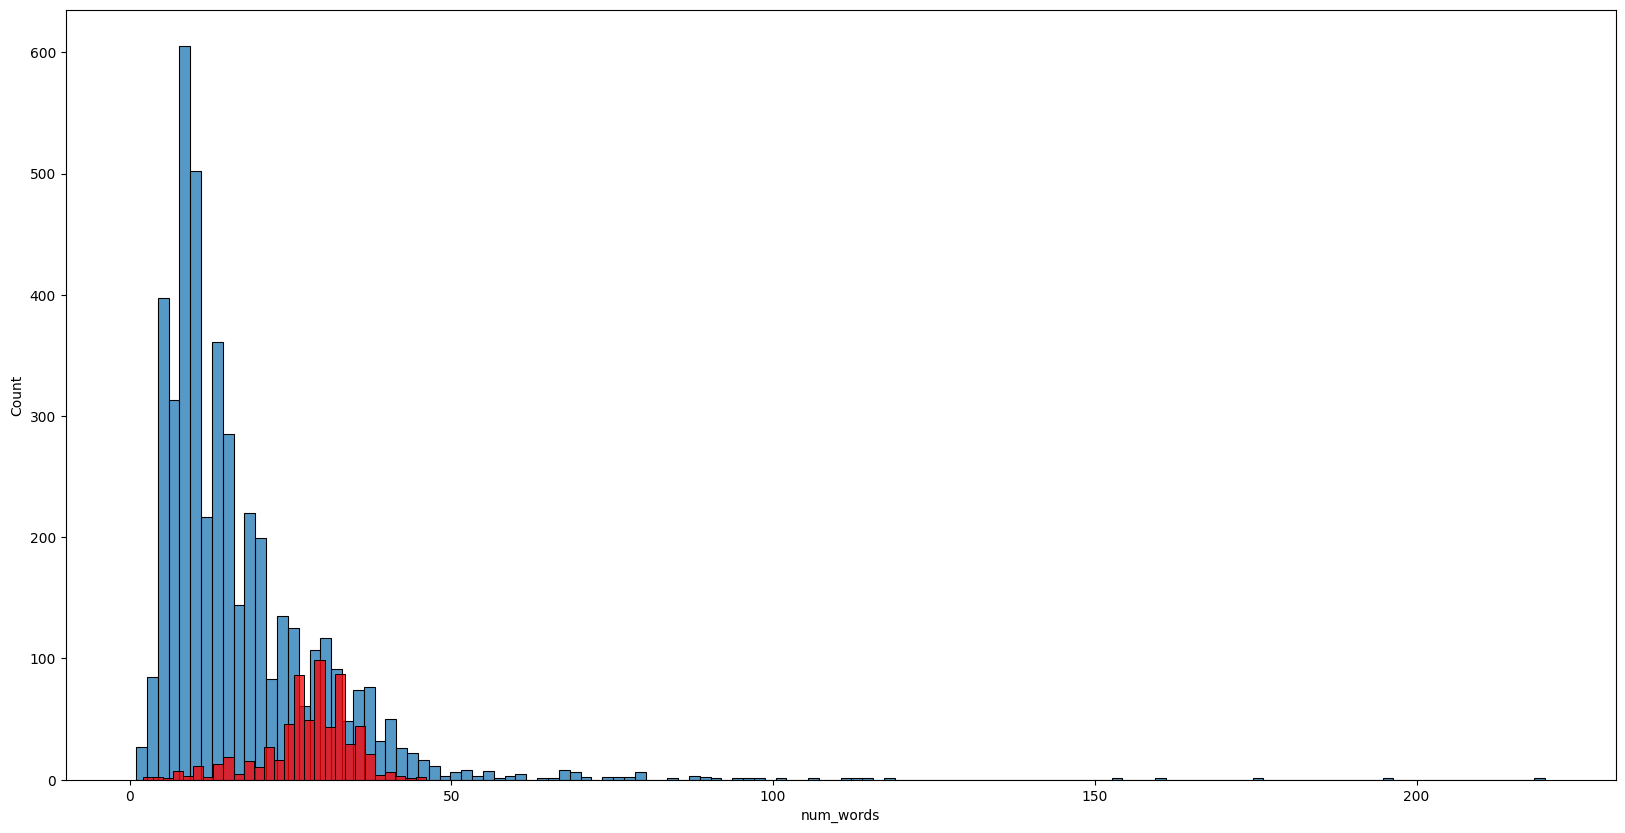

In [22]:
plt.figure(figsize=(20,10))
sns.histplot(df[df['target']==0]['num_words'])
sns.histplot(df[df['target']==1]['num_words'],color='red')

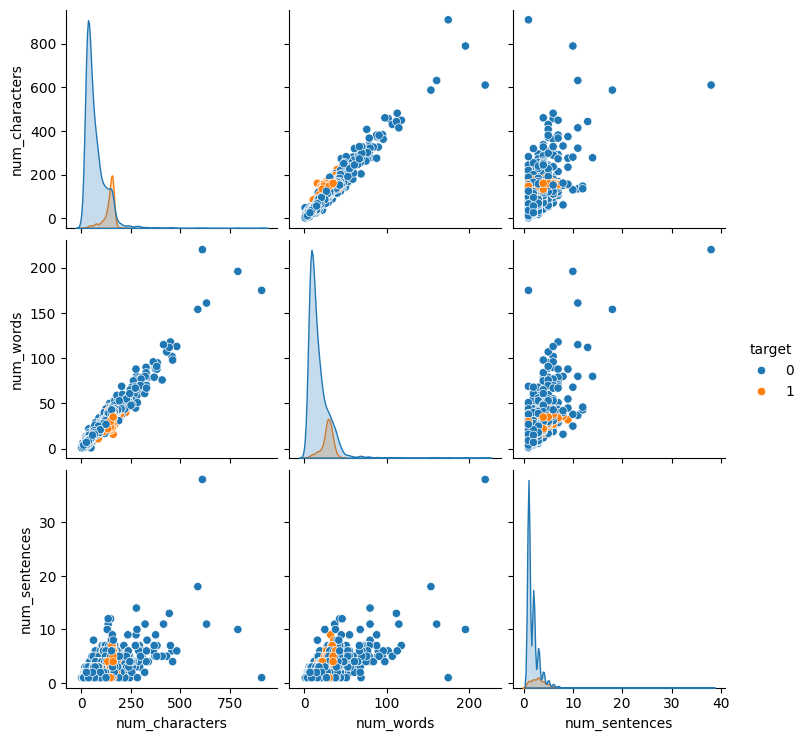

In [23]:
sns.pairplot(data=df,hue='target')

<Axes: >

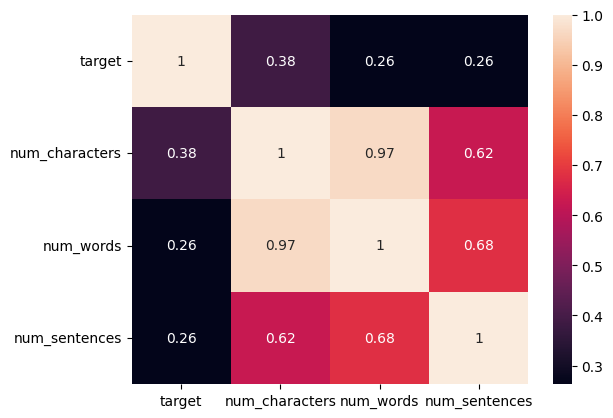

In [24]:
sns.heatmap(df.drop('text',axis=1).corr(),annot=True)

# Data Preprocessing

In [ ]:
def transform_text(text):
    text=text.lower()
    text=nltk.word_tokenize(text)

    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)
    text=y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    text=y[:]
    y.clear()
    
    ps=PorterStemmer()
    for i in text:
        
        y.append(ps.stem(i))
    return ' '.join(y)

In [26]:
df['transformed_text']=df['text'].apply(transform_text)

In [27]:
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')

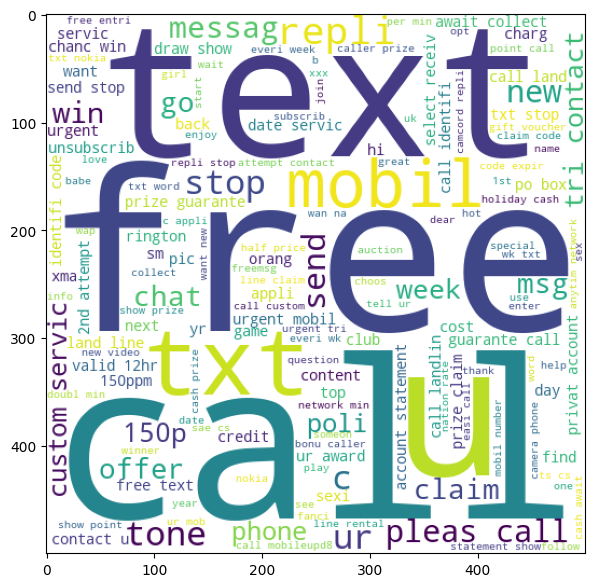

In [28]:
spam_wc=wc.generate(df[df['target']==1]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(20,7))
plt.imshow(spam_wc)

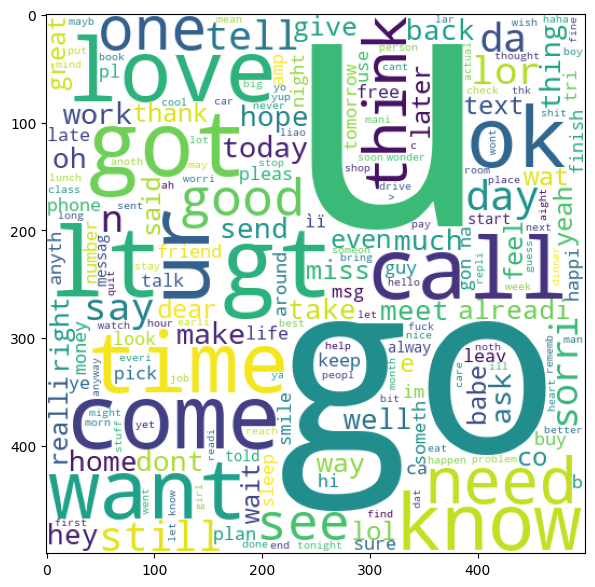

In [29]:
ham_wc=wc.generate(df[df['target']==0]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(20,7))
plt.imshow(ham_wc)

In [30]:
# splitting sentences into single word
spam_corpus=[]
for i in df[df['target']==1]['transformed_text'].tolist():
    for word in i.split():
        spam_corpus.append(word)
len(spam_corpus)



9939

In [31]:
ham_corpus=[]
for i in df[df['target']==0]['transformed_text'].tolist():
    for word in i.split():
        ham_corpus.append(word)
len(ham_corpus)


35404

In [73]:
pd.DataFrame(Counter(spam_corpus).most_common(30))

,0,1
0,call,320
1,free,191
2,2,155
3,txt,141
4,text,122
5,u,119
6,ur,119
7,mobil,114
8,stop,104
9,repli,103


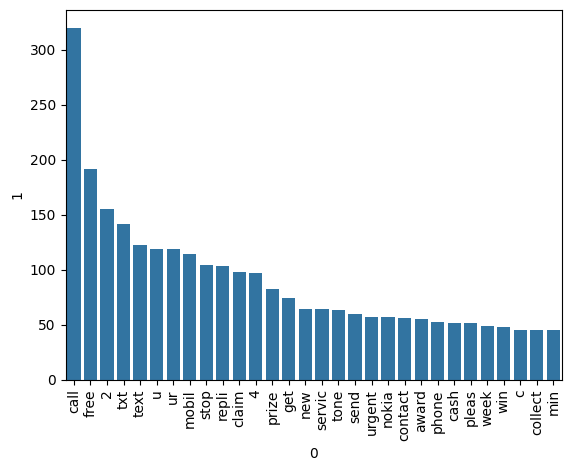

In [33]:
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

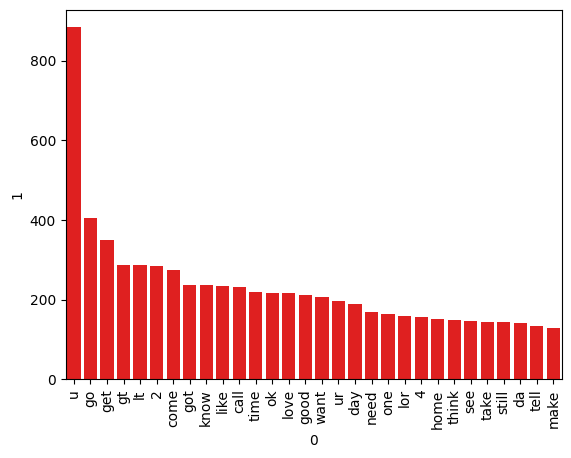

In [34]:
sns.barplot(x=pd.DataFrame(Counter(ham_corpus).most_common(30))[0],y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1],color='red')
plt.xticks(rotation='vertical')
plt.show()

# Model Buliding

In [35]:
cv=CountVectorizer()
X=cv.fit_transform(df['transformed_text']).toarray()
y=df['target'].values

In [55]:
tfidf=TfidfVectorizer(max_features=3000)
X=tfidf.fit_transform(df['transformed_text']).toarray()
y=df['target'].values

In [56]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [57]:

clf1=GaussianNB()
clf2=MultinomialNB()
clf3=BernoulliNB()

In [58]:
clf1.fit(X_train,y_train)
clf2.fit(X_train,y_train)
clf3.fit(X_train,y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [59]:
y_pred1=clf1.predict(X_test)
y_pred2=clf2.predict(X_test)
y_pred3=clf3.predict(X_test)

In [60]:
def metrics(y_test,y_pred):
    acc=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred)
    con_mat=confusion_matrix(y_test,y_pred)

    print(f'accuracy_score = {acc}')
    print(f'precision = {precision}')
    # print(f'confusion metrix  {con_mat}')
    return con_mat

In [61]:
print('gaussiannb score',)
print(metrics(y_test,y_pred1))

gaussiannb score
accuracy_score = 0.8733075435203095
precision = 0.5159817351598174
[[790 106]
 [ 25 113]]


In [62]:
print('multinomialnb score',)
print(metrics(y_test,y_pred2))

multinomialnb score
accuracy_score = 0.9709864603481625
precision = 1.0
[[896   0]
 [ 30 108]]


In [63]:
print('bernoullinb score',)
print(metrics(y_test,y_pred3))

bernoullinb score
accuracy_score = 0.9835589941972921
precision = 0.991869918699187
[[895   1]
 [ 16 122]]


In [64]:
svc=SVC(kernel='sigmoid',gamma=1.0)
knc=KNeighborsClassifier()
mnb=MultinomialNB()
dtc=DecisionTreeClassifier(max_depth=5)
lrc=LogisticRegression(solver='liblinear',penalty='l1')
rfc=RandomForestClassifier(n_estimators=50,random_state=2)
abc=AdaBoostClassifier(n_estimators=50,random_state=2)
bc=BaggingClassifier(n_estimators=50,random_state=2)
etc=ExtraTreesClassifier(n_estimators=50,random_state=2)
gbdt=GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb=XGBClassifier(n_estimator=50,random_state=2)


In [66]:
clfs={
    'SVC':svc,
    'KN':knc,
    'NB':mnb,
    'DT':dtc,
    'LR':lrc,
    'RF':rfc,
    'AdaBoost':abc,
    'BTC':bc,
    'ETC':etc,
    'GBDT':gbdt,
    'xgb': xgb

}

In [67]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred)

    return accuracy,precision

In [68]:
train_classifier(svc,X_train,y_train,X_test,y_test)

(0.9758220502901354, 0.9747899159663865)

In [69]:
accuracy_scores=[]
precision_scores=[]
for name,clf in clfs.items():
    current_accuracy,current_precision=train_classifier(clf,X_train,y_train,X_test,y_test)

    print('For',name)
    print('accuracy -',current_accuracy)
    print('precision -',current_precision)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For SVC
accuracy - 0.9758220502901354
precision - 0.9747899159663865
For KN
accuracy - 0.9052224371373307
precision - 1.0
For NB
accuracy - 0.9709864603481625
precision - 1.0
For DT
accuracy - 0.9303675048355899
precision - 0.8367346938775511
For LR
accuracy - 0.9564796905222437
precision - 0.9696969696969697
For RF
accuracy - 0.97678916827853
precision - 0.975
For AdaBoost
accuracy - 0.9235976789168279
precision - 0.8390804597701149
For BTC
accuracy - 0.9593810444874274
precision - 0.8692307692307693
For ETC
accuracy - 0.9777562862669246
precision - 0.967479674796748
For GBDT
accuracy - 0.9506769825918762
precision - 0.9306930693069307


c:\Users\saura\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:183: UserWarning: [12:54:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


For xgb
accuracy - 0.9748549323017408
precision - 0.9516129032258065


In [50]:
performance_df=pd.DataFrame({'algorithm':clfs.keys(),'accuracy':accuracy_scores,'precision':precision_scores})

In [51]:
performance_df.sort_values('precision',ascending=False)

,algorithm,accuracy,precision
1,KN,0.906190,1.000000
5,RF,0.971954,1.000000
8,ETC,0.976789,0.991379
10,xgb,0.978723,0.975410
4,LR,0.970986,0.973684
3,DT,0.927466,0.956522
9,GBDT,0.943907,0.944444
6,AdaBoost,0.919729,0.936508
7,BTC,0.962282,0.915966
2,NB,0.964217,0.834437


In [52]:
# performance_df1=pd.melt(performance_df,id_vars='algorithm')

In [70]:
temp_df=pd.DataFrame({'algorithm':clfs.keys(),'accuracy_tidf':accuracy_scores,'precision_tidf':precision_scores})

In [71]:
performance_df.merge(temp_df,on='algorithm')

,algorithm,accuracy,precision,accuracy_tidf,precision_tidf
0,SVC,0.926499,0.742188,0.975822,0.974790
1,KN,0.906190,1.000000,0.905222,1.000000
2,NB,0.964217,0.834437,0.970986,1.000000
3,DT,0.927466,0.956522,0.930368,0.836735
4,LR,0.970986,0.973684,0.956480,0.969697
5,RF,0.971954,1.000000,0.976789,0.975000
6,AdaBoost,0.919729,0.936508,0.923598,0.839080
7,BTC,0.962282,0.915966,0.959381,0.869231
8,ETC,0.976789,0.991379,0.977756,0.967480
9,GBDT,0.943907,0.944444,0.950677,0.930693


In [72]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))